In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

GausianNB 는 가우시안 정규분포를 활용하여 데이터를 분류한다.
붗꽃 종류를 판별하는데 활용해 보자

In [ ]:
#1. 데이터 호출
iris = load_iris()
print(f'data keys : {iris.keys()}')
print(f'feature name : {iris.feature_names}')
print(f'target name : {iris.target_names}')

data keys : dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
feature name : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
target name : ['setosa' 'versicolor' 'virginica']


In [ ]:
# 원리를 살펴보자! - 우선 setosa 종을 구분하는 방법
# 가져온 데이터 에서 특성들과 답을 한번에 dataframe 화 시킨다.
df = pd.DataFrame(iris.data, columns=iris.feature_names)
# df.head()

df['target'] = iris.target
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
# 종별로 분류(target 값 별로...)
setosa = df[df.target == 0]
versicolor = df[df.target == 1]
virginica = df[df.target == 2]

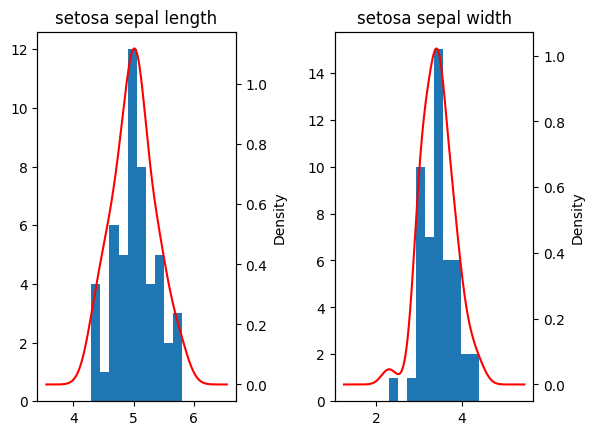

In [ ]:
# setosa 품종에 대한 꽃받침(sepal) 길이(length) 분포
data = setosa['sepal length (cm)']

plt.subplot(121)
plt.title('setosa sepal length')
plt.hist(data)
plt.twinx()

# KDE 는 정규분포 그래프다.
data.plot(kind='kde', color='red')

plt.subplot(122)
plt.title('setosa sepal width')
data = setosa['sepal width (cm)']
plt.hist(data)
plt.twinx()

# KDE 는 정규분포 그래프다.
data.plot(kind='kde', color='red')
plt.subplots_adjust(wspace=0.5)

plt.show()

이처럼 특정한 target 의 값들을 모아 정규 분포를 통해 구분의 근거를 삼는다.

In [ ]:
from sklearn.naive_bayes import GaussianNB
# 1. 데이터 분리
x_train, x_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, random_state=33)

# 2. 트레이닝
nb = GaussianNB().fit(x_train, y_train)

# 3. 예측 또는 점수측정
print(f'train score : {nb.score(x_train, y_train):.2f}')
print(f'test score : {nb.score(x_test, y_test):.2f}')

train score : 0.96
test score : 0.96
